# Assignment 4, Part 2: References and citations

If matplotlib is missing, run
`%pip install matplotlib` in a separate notebook cell first.


In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt


## 1. Read the article

Find the repository from the current working directory or one of its parents.



In [2]:
possible_roots = [Path.cwd(), *Path.cwd().parents]
repo_root = next(
    (folder for folder in possible_roots
     if (folder / "assignments/materials/week_4/article_preprint.txt").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the MAN7916 repository or its assignment_4 folder.")

article_path = repo_root / "assignments/materials/week_4/article_preprint.txt"
output_folder = repo_root / "assignments/submissions/assignment_4"
output_folder.mkdir(parents=True, exist_ok=True)

article_text = article_path.read_text(encoding="utf-8")

# If the file includes a References heading, exclude the bibliography from counts.
body_text = re.search(
    r"\A.*?(?=^\s*(?:\d+[.)]?\s*)?References\s*$|\Z)",
    article_text,
    flags=re.MULTILINE | re.DOTALL | re.IGNORECASE,
).group()

# Normalize line breaks and spaces
body_text = re.sub(r"\s+", " ", body_text)
print(f"Reading: {article_path}")


Reading: c:\Research\Subjects\content analysis\MAN7916-main\assignments\materials\week_4\article_preprint.txt


## 2. Define the citation patterns

The patterns allow accented and hyphenated names, multiword surnames, `et al.`,
two authors joined by `&` or `and`, and year suffixes such as `2018a`.
The author/year captures leave out prefixes (`e.g.`, `see`) and page numbers.

The sorting helper changes only a temporary sort key. Original spelling and
accents remain in the report. Its accent mapping covers the names in this article.


In [3]:
year_pattern = r"(?:19|20)\d{2}[a-z]?"
years_pattern = rf"{year_pattern}(?:\s*,\s*{year_pattern})*"

name_word = r"[A-ZÀ-ÖØ-Þ][^\W\d_]*(?:[-'’][^\W\d_]+)*"
surname_pattern = rf"{name_word}(?:\s+(?:{name_word}|de|del|van|von))*"
authors_pattern = (
    rf"{surname_pattern}"
    rf"(?:\s+et\s+al\.|\s+(?:&|and)\s+{surname_pattern})?"
)

names_dates_pattern = rf"\b({authors_pattern})\s*,\s*({years_pattern})\b"

def clean_spacing(text):
    text = re.sub(r"\s+", " ", text)
    return re.sub(r"^\s+|\s+$", "", text)

def alphabetical_key(text):
    accents = {"é": "e", "É": "e", "ö": "o", "Ö": "o"}
    text = re.sub(r"[éÉöÖ]", lambda match: accents[match.group()], text)
    return re.sub(r"[A-Z]", lambda match: chr(ord(match.group()) + 32), text)


## 3. Extract names-and-dates citations

This first finds each parenthetical group. Then it finds
the author/year citations inside each group.


In [4]:
parenthetical_groups = re.findall(r"\(([^()]*)\)", body_text)
names_and_dates_citations = []

for group in parenthetical_groups:
    matches = re.findall(names_dates_pattern, group)
    for authors, years in matches:
        authors = clean_spacing(authors)
        for year in re.findall(year_pattern, years):
            names_and_dates_citations.append(f"{authors}, {year}")

citation_counts = Counter(names_and_dates_citations)
unique_names_and_dates = sorted(set(names_and_dates_citations), key=alphabetical_key)

print(f"Names-and-dates occurrences: {len(names_and_dates_citations)}")
print(f"Unique names-and-dates references: {len(unique_names_and_dates)}")


Names-and-dates occurrences: 276
Unique names-and-dates references: 139


## 4. Extract date-only citations with context

This keep ups to 50 characters before the
parenthesized year. The excerpt may begin in the middle of a word, but includes
the nearby author's name.
The small author match below is used to alphabetize and deduplicate these
excerpts by author and year.


In [5]:
date_only_pattern = rf"(?P<context>.{{0,50}})\((?P<years>{years_pattern})\)"
date_only_by_reference = {}

for match in re.finditer(date_only_pattern, body_text):
    context = clean_spacing(match.group("context"))
    # Remove a final possessive from the sort/deduplication key: Hofstede’s -> Hofstede.
    author_context = re.sub(r"['’]s\s*$", "", context)
    author_match = re.search(rf"({authors_pattern})\s*$", author_context)
    if author_match is None:
        raise ValueError(f"Review this date-only citation: {match.group()}")
    authors = clean_spacing(author_match.group(1))
    for year in re.findall(year_pattern, match.group("years")):
        key = f"{authors}, {year}"
        # Different contextual excerpts for the same article produce one report row.
        if key not in date_only_by_reference:
            date_only_by_reference[key] = f"{context} ({year})"

date_only_keys = sorted(date_only_by_reference, key=alphabetical_key)
unique_date_only = [date_only_by_reference[key] for key in date_only_keys]

print(f"Unique date-only references: {len(unique_date_only)}")
for citation in unique_date_only:
    print(citation)


Unique date-only references: 5
eotype against black entrepreneurs. Anglin et al. (2018b)
pes than others. For instance, Balachandra et al. (2019)
Löckenhoff et al., 2009). Building on Hofstede’s (2011)
crowdfunding campaigns. Similarly, Johnson et al. (2018)
er decisions. For example, Younkin and Kuppuswamy (2018)


## 5. Plot the 20 most common parenthetical citations

This follows the tutorial's `Counter.most_common()` and matplotlib workflow, using a
bar chart here. The most frequent citation is on the left.


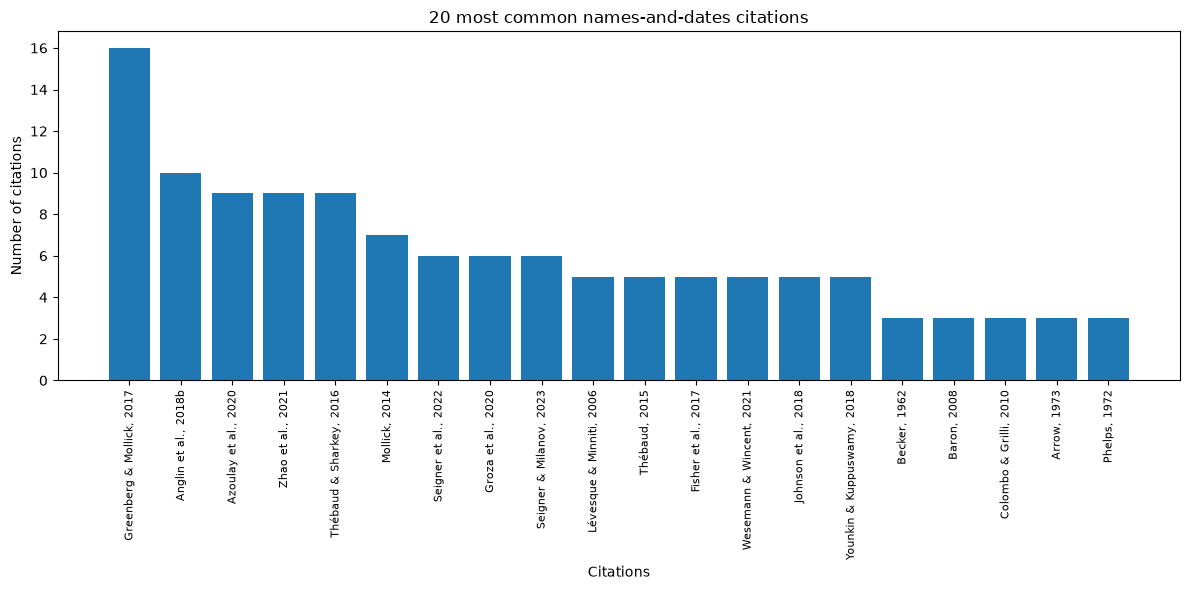

Saved: c:\Research\Subjects\content analysis\MAN7916-main\assignments\submissions\assignment_4\common_citations.jpg


In [6]:
top_20 = citation_counts.most_common(20)
if not top_20:
    raise ValueError("No names-and-dates citations were found.")

citations, frequencies = zip(*top_20)
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(citations, frequencies)
ax.set_xlabel("Citations")
ax.set_ylabel("Number of citations")
ax.set_title("20 most common names-and-dates citations")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
fig.tight_layout()

chart_path = output_folder / "common_citations.jpg"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved: {chart_path}")


## 6. Write the reference checklist

Keep the two citation types in separate, alphabetized sections, with one row
per unique reference within each section. A reference appearing in both citation
styles appears once in each section. As in the sample report, this is a checklist
of references to look for, rather than an automatic missing-reference verdict.


In [7]:
report_path = output_folder / "references_report.txt"

with report_path.open("w", encoding="utf-8") as report:
    report.write("Names-and-dates references:\n")
    report.write("=" * 50 + "\n")
    for citation in unique_names_and_dates:
        report.write(f"{citation}\n")
    report.write("\nDate-only references:\n")
    report.write("=" * 50 + "\n")
    for citation in unique_date_only:
        report.write(f"{citation}\n")

print(f"Saved: {report_path}")


Saved: c:\Research\Subjects\content analysis\MAN7916-main\assignments\submissions\assignment_4\references_report.txt
